### Problem Statement: Vehicle Type Classification

To demonstrate how an MLP performs classification in the wild, let's build a **Vehicle Category Classification System**.

Imagine you are working with an automated toll or traffic monitoring system. Sensors capture numerical telemetry data for passing vehicles. Our goal is to train an MLP to classify each vehicle into one of three categories:

1. **Compact/Sedan** (Class 0)
2. **SUV/Crossover** (Class 1)
3. **Heavy Commercial Truck** (Class 2)

**Input Features (4 dimensions):**

* **Weight** (in kg)
* **Length** (in meters)
* **Engine Displacement** (in CC)
* **Average Operating Speed** (in km/h)

---

### Python Implementation (Using PyTorch)

Below is a complete, clean implementation using **PyTorch**, which lets us define the neural network architecture explicitly and walk through the training loop.

---

### Key Takeaways from the Code

* **`nn.Sequential` & `nn.Linear**`: We stacked an input layer (4 features) to a hidden layer of 32 neurons, applied a **ReLU** activation function, added a **Dropout** layer for regularization, passed it through another hidden layer, and finally mapped it to 3 output nodes (representing our 3 vehicle classes).
* **Cross-Entropy Loss**: In PyTorch, `nn.CrossEntropyLoss()` automatically applies the **Softmax** function internally to the raw output logits during loss calculation, making it ideal for multi-class classification.
* **Feature Scaling (`StandardScaler`)**: Neural networks update weights using gradients. If one feature (e.g., vehicle weight in kg like 2000) is on a vastly different scale than another (length in meters like 4.5), gradient descent will struggle to converge. Standardization puts all features on an equal playing field.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np

### Explanation: Importing Required Libraries

In this cell, we import all the necessary modules to build, train, and evaluate our Multi-Layer Perceptron (MLP):
- **`torch` & `torch.nn` / `torch.optim`**: PyTorch's core library, neural network layers (`nn`), and optimization algorithms (`optim`).
- **`make_classification`**: From `scikit-learn`, used to generate a realistic synthetic dataset for multi-class classification.
- **`train_test_split`**: Splits our dataset into training and testing portions to ensure clean evaluation.
- **`StandardScaler`**: Scales our input features to have a mean of 0 and a variance of 1, which helps gradient descent converge faster.

In [ ]:
# 1. Generate Synthetic Vehicle Telemetry Dataset
# 4 features (weight, length, displacement, speed), 3 classes (Sedan, SUV, Truck)
X_raw, y_raw = make_classification(
    n_samples=1500,
    n_features=4,
    n_informative=4,
    n_redundant=0,
    n_classes=3,
    random_state=42
)

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y_raw, test_size=0.2, random_state=42
)

### Explanation: Synthetic Dataset Generation & Splitting

This step sets up our training and testing data:
- **Dataset Creation**: We generate a dataset of $1500$ samples. Each sample has $4$ features (representing vehicle parameters like Weight, Length, Engine Displacement, and Operating Speed) mapped to $3$ distinct classes.
- **Train-Test Split**: We reserve $20\%$ of our data ($300$ samples) for evaluation (`X_test`, `y_test`) and keep the remaining $80\%$ ($1200$ samples) to train our network (`X_train`, `y_train`).

In [ ]:
# 2. Preprocess Data (Standardization is crucial for MLPs)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert to PyTorch Tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

### Explanation: Feature Scaling & PyTorch Tensor Conversion

Before passing numerical data into a PyTorch model, we must preprocess it:
- **`StandardScaler`**: We fit the scaler on the training set and transform both the training and testing sets. This ensures features with large numbers (like Weight in kg) don't overpower smaller features (like Length in meters).
- **Tensor Conversion**: PyTorch models do not natively accept NumPy arrays. We explicitly convert the data into standard PyTorch floats (`torch.float32`) for features, and integers (`torch.long`) for target class indices.

In [ ]:
# 3. Define the MLP Architecture
class VehicleMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super(VehicleMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(0.2),  # Prevents overfitting
            nn.Linear(hidden_dim, 16),
            nn.ReLU(),
            nn.Linear(16, output_dim) # Raw logits output (no Softmax needed here because CrossEntropyLoss handles it)
        )

    def forward(self, x):
        return self.network(x)

# Initialize model, loss function, and optimizer
input_features = 4
hidden_neurons = 32
num_classes = 3

model = VehicleMLP(input_dim=input_features, hidden_dim=hidden_neurons, output_dim=num_classes)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

### Explanation: Defining the MLP Network Architecture

Here we construct the neural network and define how data passes through it:
- **`VehicleMLP` Class**: Extends PyTorch's `nn.Module` class.
- **Sequential Layers**: We define a chain of layers:
  1. An input layer accepting 4 dimensions mapped to 32 hidden units.
  2. A **ReLU** non-linear activation.
  3. A **Dropout (0.2)** layer, which randomly deactivates $20\%$ of neurons during training to prevent overfitting.
  4. A second hidden layer mapping from 32 to 16 units, followed by another ReLU.
  5. An output layer mapping 16 units to the 3 target classes.
- **Loss Function & Optimizer**: We instantiate the model, use `nn.CrossEntropyLoss` (which handles Softmax mapping automatically), and choose the `Adam` optimizer with a learning rate of `0.01`.

In [ ]:
# 4. Training Loop
epochs = 100
for epoch in range(epochs):
    model.train()

    # Forward pass
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)

    # Backward pass and optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch + 1) % 20 == 0:
        print(f"Epoch [{epoch+1}/{epochs}], Loss: {loss.item():.4f}")

Epoch [20/100], Loss: 0.5883
Epoch [40/100], Loss: 0.4711
Epoch [60/100], Loss: 0.4250
Epoch [80/100], Loss: 0.3937
Epoch [100/100], Loss: 0.3721


### Explanation: Model Training Loop

This block runs the core optimization process for $100$ epochs:
- **`model.train()`**: Tells PyTorch to enable training behaviors like Dropout.
- **Forward Pass**: The model receives our training features (`X_train_t`) and outputs raw predictions (logits). The performance is measured using our `criterion` (Cross-Entropy Loss).
- **Backward Pass & Weights Update**:
  1. `optimizer.zero_grad()` clears residual gradients from the previous round.
  2. `loss.backward()` computes gradients of the loss with respect to all model weights.
  3. `optimizer.step()` updates model weights using the calculated gradients.
- **Progress Tracking**: Every 20 epochs, we print the loss value to verify that the model is converging.

In [ ]:
# 5. Evaluation
model.eval()
with torch.no_grad():
    test_outputs = model(X_test_t)
    _, predicted = torch.max(test_outputs, 1)
    accuracy = (predicted == y_test_t).sum().item() / y_test_t.size(0)
    print(f"\nTest Accuracy: {accuracy * 100:.2f}%")


Test Accuracy: 85.67%


### Explanation: Evaluating Model Accuracy

To verify if our model generalizes well to unseen data:
- **`model.eval()`**: Disables regularizations like Dropout to ensure deterministic predictions.
- **`torch.no_grad()`**: Disables gradient computation, saving memory and processing power.
- **`torch.max`**: Pulls the highest probability index (0, 1, or 2) from our raw outputs.
- **Accuracy Calculation**: Compares predictions directly to ground-truth testing labels (`y_test_t`) to output a final accuracy percentage.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

### Explanation: Visualizing Setup & Import

Here, we set up a secondary clean workspace and import the data plotting libraries (`matplotlib.pyplot`, `seaborn`, and `pandas`) alongside our PyTorch utilities. This prepares us to build our graphical representations.

In [ ]:
# --- 1. Generate & Prepare Data ---
X_raw, y_raw = make_classification(
    n_samples=1500, n_features=4, n_informative=4,
    n_redundant=0, n_classes=3, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(X_raw, y_raw, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)

### Explanation: Re-preparing Data for Visualizations

We recreate the dataset split and execute standard scaling. This ensures that the datasets are correctly configured for generating plots, clean distribution pairs, and 2D sliced decision boundaries.

In [ ]:
# --- 2. Define & Train MLP (Tracking Loss) ---
class VehicleMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(4, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 3)
        )
    def forward(self, x):
        return self.network(x)

model = VehicleMLP()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

epochs = 100
loss_history = []

for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()
    outputs = model(X_train_t)
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

model.eval()

VehicleMLP(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Linear(in_features=16, out_features=3, bias=True)
  )
)

### Explanation: Visual Training with Loss Tracking

This block performs model training similar to our previous training loop, but with an important addition:
- **`loss_history` Tracking**: In every epoch, we capture the loss value (`loss.item()`) and append it to a list. This allows us to map and plot the convergence slope of our model.

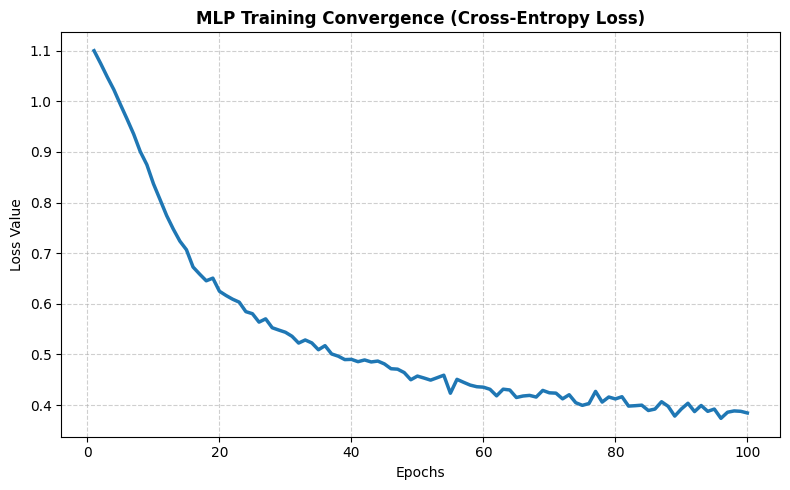

In [ ]:
# ==========================================
# VISUALIZATION 1: Training Loss Curve
# ==========================================
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), loss_history, color='#1f77b4', linewidth=2.5)
plt.title('MLP Training Convergence (Cross-Entropy Loss)', fontsize=12, fontweight='bold')
plt.xlabel('Epochs', fontsize=10)
plt.ylabel('Loss Value', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Explanation: Plotting the Loss Curve

Using the tracked `loss_history` array, we produce a linear plot showing how training loss drops over $100$ epochs. A smooth, downward-curving line indicates successful optimization.

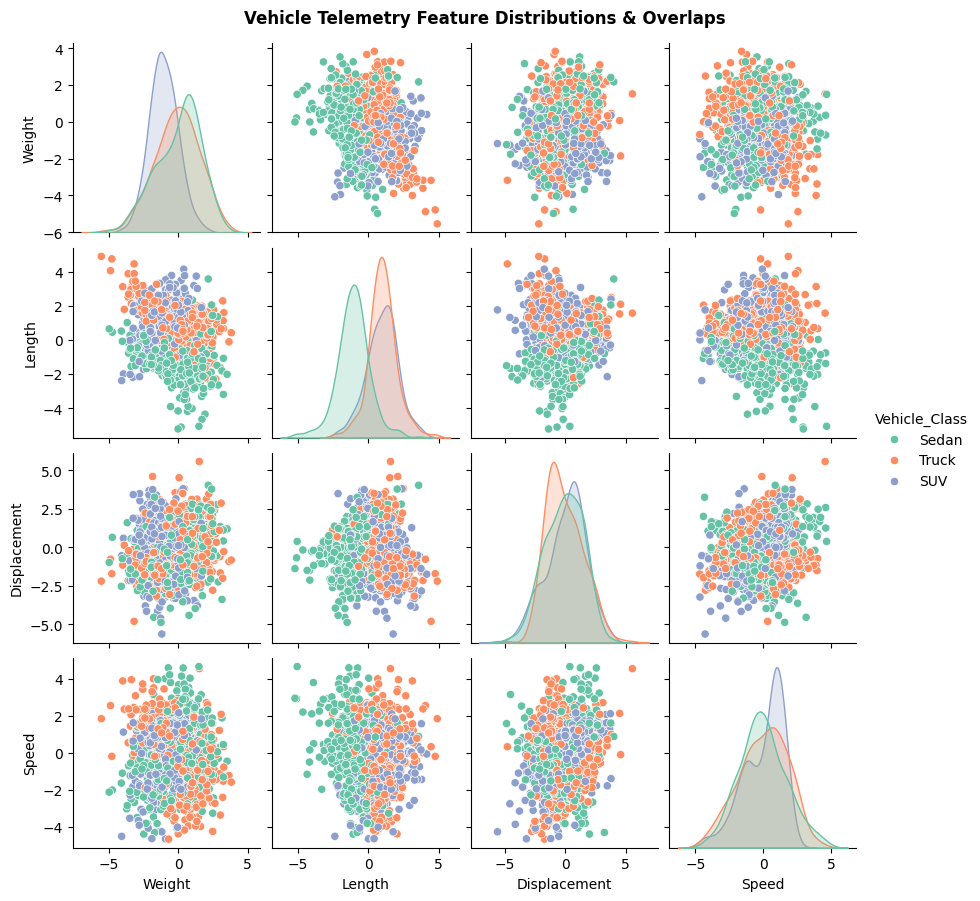

In [ ]:
# ==========================================
# VISUALIZATION 2: Feature Distributions (Pairplot)
# ==========================================
import pandas as pd
df = pd.DataFrame(X_train, columns=['Weight', 'Length', 'Displacement', 'Speed'])
df['Vehicle_Class'] = y_train
class_labels = {0: 'Sedan', 1: 'SUV', 2: 'Truck'}
df['Vehicle_Class'] = df['Vehicle_Class'].map(class_labels)

sns.pairplot(df, hue='Vehicle_Class', palette='Set2', diag_kind='kde', height=2.2)
plt.suptitle('Vehicle Telemetry Feature Distributions & Overlaps', y=1.02, fontsize=12, fontweight='bold')
plt.show()

### Explanation: Plotting Feature Pairwise Distributions

To better understand our synthetic data, we organize our raw dataset into a `pandas.DataFrame` and replace numeric classes (0, 1, 2) with friendly names ('Sedan', 'SUV', 'Truck'). Using `sns.pairplot`, we render distributions of individual features and bivariate relationships, showing how classes overlap in space.

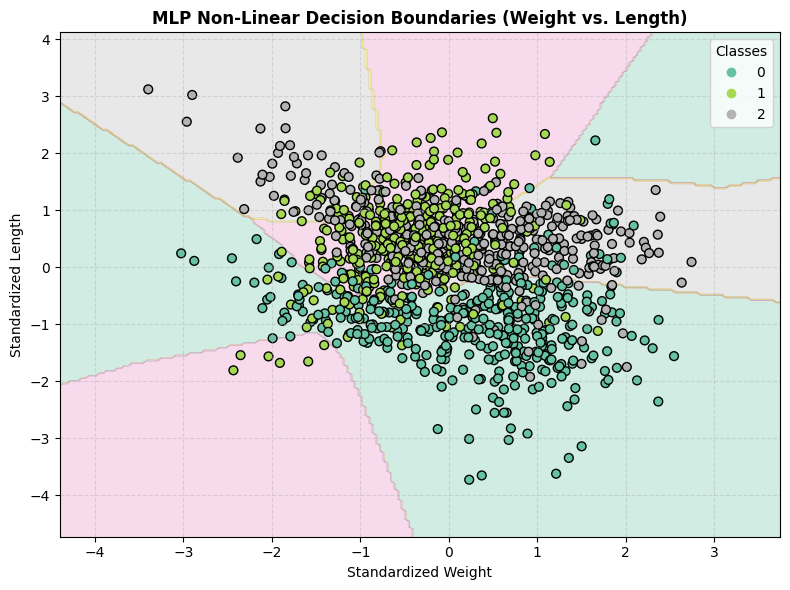

In [ ]:
# ==========================================
# VISUALIZATION 3: MLP Decision Boundaries (2D Slice)
# ==========================================
# Train a 2-feature subset for easy 2D visualization (Weight vs Length)
X_2d = X_train_scaled[:, :2]
model_2d = nn.Sequential(
    nn.Linear(2, 32), nn.ReLU(),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 3)
)
optimizer_2d = optim.Adam(model_2d.parameters(), lr=0.02)
y_train_2d = torch.tensor(y_train, dtype=torch.long)

for _ in range(150):
    optimizer_2d.zero_grad()
    loss = nn.CrossEntropyLoss()(model_2d(torch.tensor(X_2d, dtype=torch.float32)), y_train_2d)
    loss.backward()
    optimizer_2d.step()

# Create meshgrid
x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid_tensor = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)

with torch.no_grad():
    preds = model_2d(grid_tensor)
    Z = torch.argmax(preds, dim=1).numpy().reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.Set2)
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y_train, cmap=plt.cm.Set2, edgecolor='k', s=40)
plt.title('MLP Non-Linear Decision Boundaries (Weight vs. Length)', fontsize=12, fontweight='bold')
plt.xlabel('Standardized Weight', fontsize=10)
plt.ylabel('Standardized Length', fontsize=10)
plt.legend(*scatter.legend_elements(), title="Classes", loc="upper right")
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Explanation: Visualizing MLP Decision Boundaries in 2D

Because we cannot easily visualize a 4-dimensional boundary space, this cell trains a simplified, 2-feature model (using only Weight and Length) and plots its classification regions:
- **Grid Generation**: We use `np.meshgrid` to generate thousands of coordinates across the 2D plane.
- **Boundary Contour mapping**: We feed all these coordinates through the trained model to predict their corresponding class. We then plot the regions using a colored backdrop (`plt.contourf`) and overlay our original data points. This lets us visually see the non-linear boundaries created by the neural network layers.